In [1]:
import shap
print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


In [3]:
import pandas as pd
import numpy as np
import shap
import joblib
import matplotlib.pyplot as plt

# Load trained model
model = joblib.load("../models/best_gradient_boosting.pkl")

# Load cleaned dataset
df = pd.read_csv("../data/processed/telco_churn_clean.csv")

print("Model loaded successfully!")
print("Dataset shape:", df.shape)

Model loaded successfully!
Dataset shape: (7043, 21)


In [4]:
X = df.drop(["Churn", "customerID"], axis=1)
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 19)
Target shape: (7043,)


In [5]:
# Select 200 customers for SHAP analysis
X_sample = X.sample(n=200, random_state=42)

# Apply the preprocessing pipeline
X_processed = model.named_steps["preprocessor"].transform(X_sample)

print("Original sample shape:", X_sample.shape)
print("Processed sample shape:", X_processed.shape)

Original sample shape: (200, 19)
Processed sample shape: (200, 45)


In [6]:
explainer = shap.TreeExplainer(
    model.named_steps["classifier"]
)

shap_values = explainer.shap_values(X_processed)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


In [7]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

print("Total features:", len(feature_names))
print(feature_names)

Total features: 45
['num__SeniorCitizen' 'num__tenure' 'num__MonthlyCharges'
 'num__TotalCharges' 'cat__gender_Female' 'cat__gender_Male'
 'cat__Partner_No' 'cat__Partner_Yes' 'cat__Dependents_No'
 'cat__Dependents_Yes' 'cat__PhoneService_No' 'cat__PhoneService_Yes'
 'cat__MultipleLines_No' 'cat__MultipleLines_No phone service'
 'cat__MultipleLines_Yes' 'cat__InternetService_DSL'
 'cat__InternetService_Fiber optic' 'cat__InternetService_No'
 'cat__OnlineSecurity_No' 'cat__OnlineSecurity_No internet service'
 'cat__OnlineSecurity_Yes' 'cat__OnlineBackup_No'
 'cat__OnlineBackup_No internet service' 'cat__OnlineBackup_Yes'
 'cat__DeviceProtection_No' 'cat__DeviceProtection_No internet service'
 'cat__DeviceProtection_Yes' 'cat__TechSupport_No'
 'cat__TechSupport_No internet service' 'cat__TechSupport_Yes'
 'cat__StreamingTV_No' 'cat__StreamingTV_No internet service'
 'cat__StreamingTV_Yes' 'cat__StreamingMovies_No'
 'cat__StreamingMovies_No internet service' 'cat__StreamingMovies_Yes'
 'c

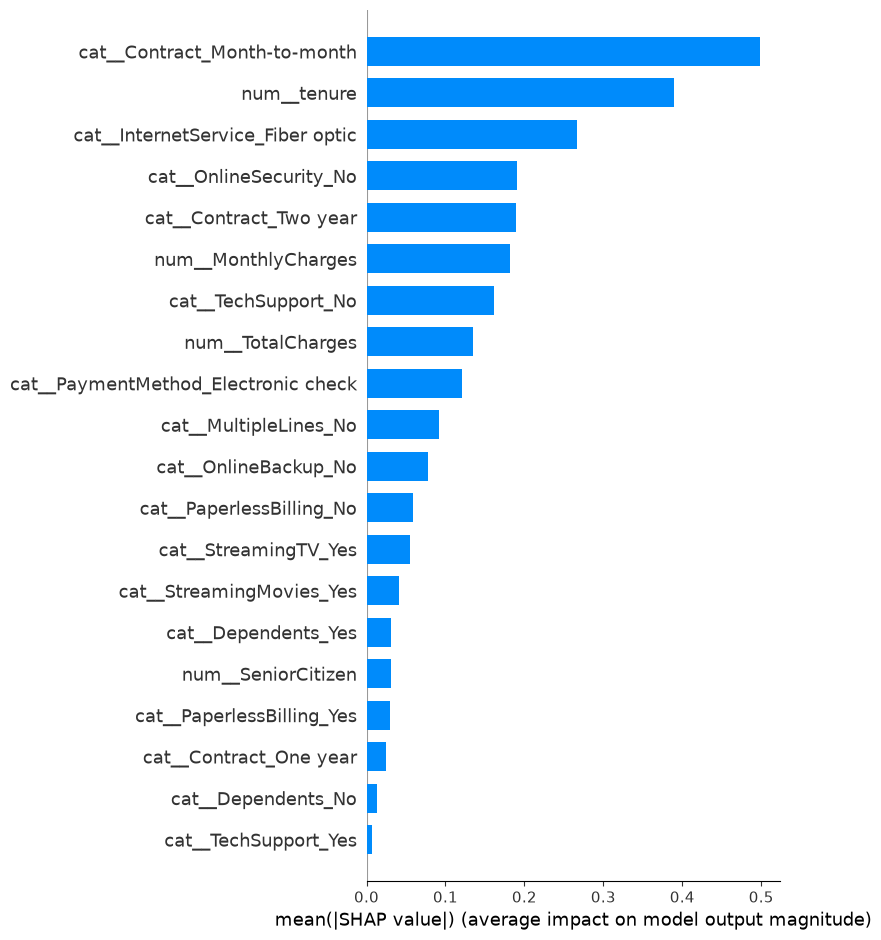

In [8]:
shap.summary_plot(
    shap_values,
    X_processed,
    feature_names=feature_names,
    plot_type="bar"
)

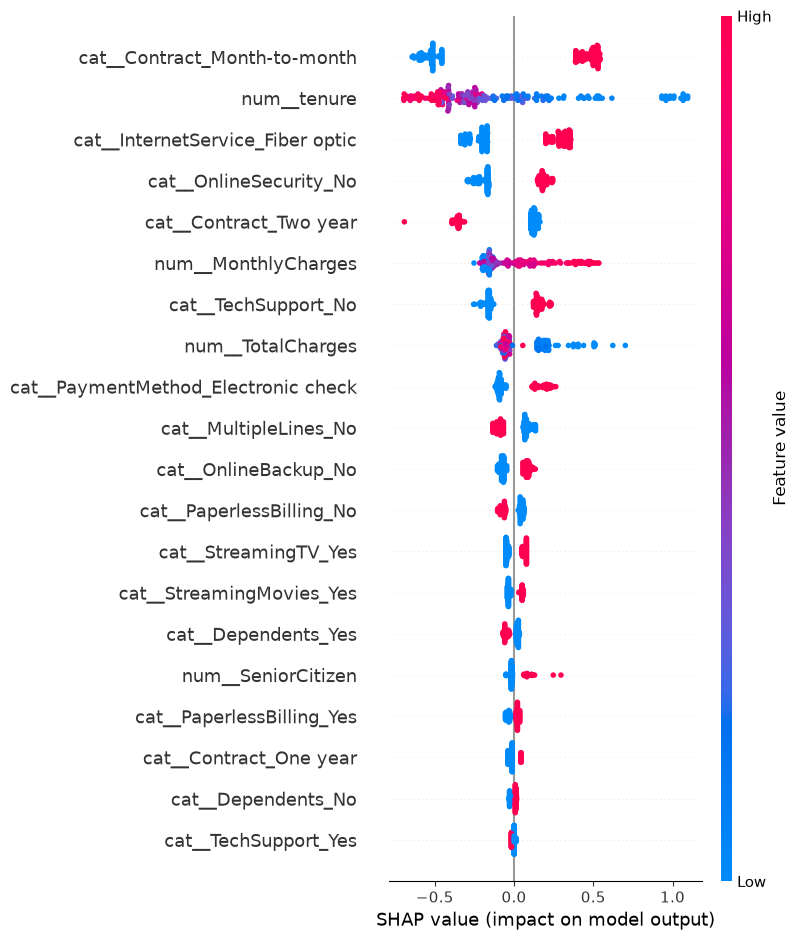

In [9]:
shap.summary_plot(
    shap_values,
    X_processed,
    feature_names=feature_names
)

In [10]:
# Calculate mean absolute SHAP values
shap_importance = np.abs(shap_values).mean(axis=0)

# Create feature importance DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": shap_importance
})

# Sort in descending order
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top 10
importance_df.head(10)

,Feature,Importance
36,cat__Contract_Month-to-month,0.498800
1,num__tenure,0.389053
16,cat__InternetService_Fiber optic,0.266576
18,cat__OnlineSecurity_No,0.190246
38,cat__Contract_Two year,0.189126
2,num__MonthlyCharges,0.181560
27,cat__TechSupport_No,0.161149
3,num__TotalCharges,0.134758
43,cat__PaymentMethod_Electronic check,0.120382
12,cat__MultipleLines_No,0.091922


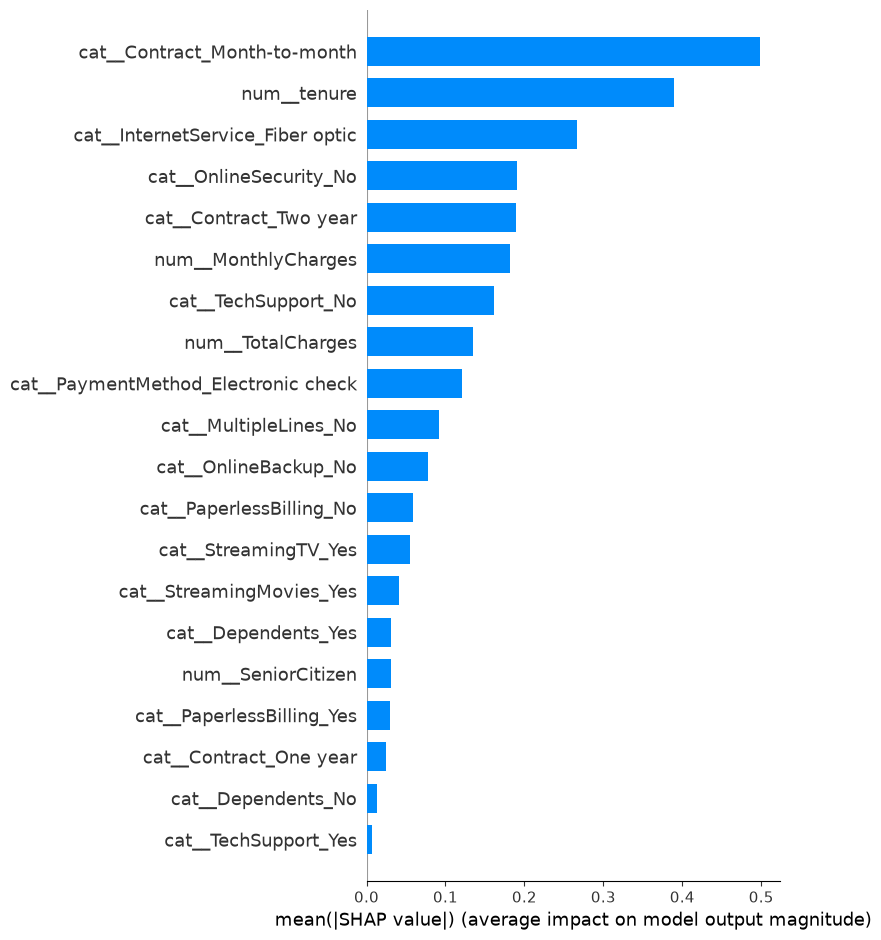

In [11]:
shap.summary_plot(
    shap_values,
    X_processed,
    feature_names=feature_names,
    plot_type="bar",
    show=False
)

plt.savefig("../reports/shap_feature_importance.png",
            bbox_inches="tight", dpi=300)
plt.show()

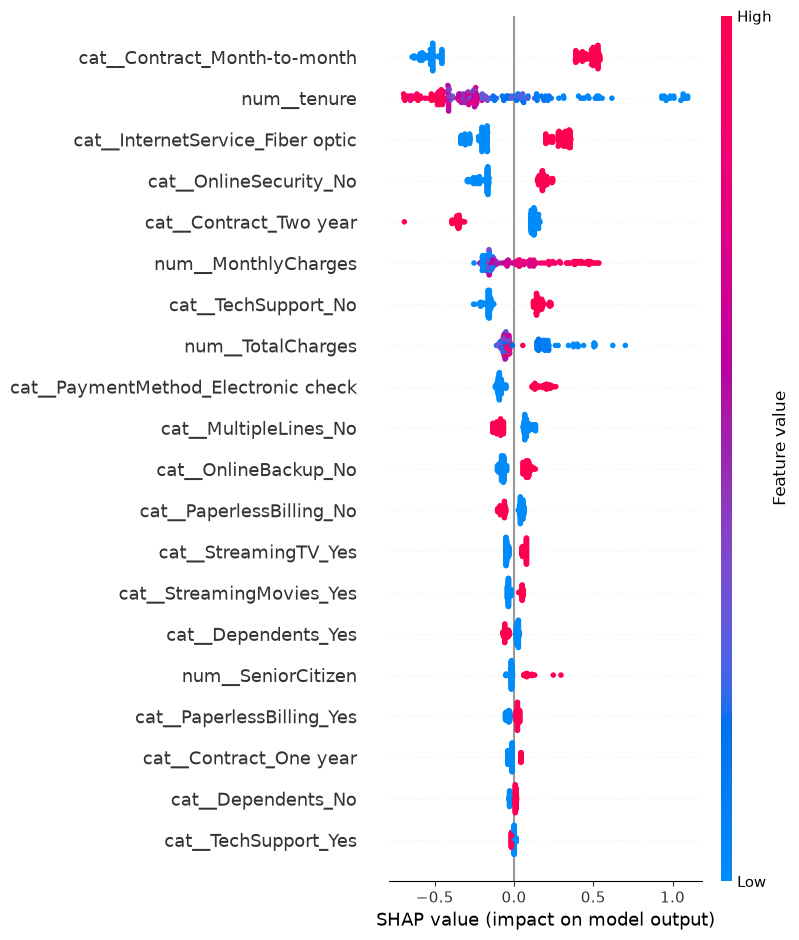

In [12]:
shap.summary_plot(
    shap_values,
    X_processed,
    feature_names=feature_names,
    show=False
)

plt.savefig("../reports/shap_beeswarm.png",
            bbox_inches="tight", dpi=300)
plt.show()

In [13]:
importance_df = importance_df.reset_index(drop=True)

importance_df.index = importance_df.index + 1

importance_df.head(10)


,Feature,Importance
1,cat__Contract_Month-to-month,0.498800
2,num__tenure,0.389053
3,cat__InternetService_Fiber optic,0.266576
4,cat__OnlineSecurity_No,0.190246
5,cat__Contract_Two year,0.189126
6,num__MonthlyCharges,0.181560
7,cat__TechSupport_No,0.161149
8,num__TotalCharges,0.134758
9,cat__PaymentMethod_Electronic check,0.120382
10,cat__MultipleLines_No,0.091922


In [14]:
print("Model classes:",
      model.named_steps["classifier"].classes_)

print("SHAP values shape:", np.array(shap_values).shape)

Model classes: ['No' 'Yes']
SHAP values shape: (200, 45)


In [15]:
# Get the model's raw prediction scores
raw_predictions = model.named_steps["classifier"].decision_function(
    X_processed
)

# Reconstruct predictions using SHAP
shap_predictions = (
    np.array(explainer.expected_value)
    + np.array(shap_values).sum(axis=1)
)

print("SHAP reconstructed scores:", shap_predictions[:5])
print("Model raw scores:", raw_predictions[:5])

print(
    "SHAP verification:",
    np.allclose(shap_predictions, raw_predictions, atol=0.001)
)

SHAP reconstructed scores: [ 0.94669477 -2.21749434 -3.91009771  1.02157252 -3.51904323]
Model raw scores: [ 0.94669477 -2.21749434 -3.91009771  1.02157252 -3.51904323]
SHAP verification: True


In [16]:
# Calculate average signed SHAP values
mean_shap = np.array(shap_values).mean(axis=0)

# Create a DataFrame
direction_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_SHAP": mean_shap
})

# Add direction
direction_df["Impact"] = np.where(
    direction_df["Mean_SHAP"] > 0,
    "Increases churn prediction",
    "Decreases churn prediction"
)

# Sort by absolute impact
direction_df["Absolute_SHAP"] = direction_df["Mean_SHAP"].abs()

direction_df = direction_df.sort_values(
    by="Absolute_SHAP",
    ascending=False
)

direction_df.head(15)

,Feature,Mean_SHAP,Impact,Absolute_SHAP
1,num__tenure,-0.111274,Decreases churn prediction,0.111274
3,num__TotalCharges,0.072111,Increases churn prediction,0.072111
36,cat__Contract_Month-to-month,0.025506,Increases churn prediction,0.025506
16,cat__InternetService_Fiber optic,0.021782,Increases churn prediction,0.021782
27,cat__TechSupport_No,-0.018027,Decreases churn prediction,0.018027
2,num__MonthlyCharges,0.012985,Increases churn prediction,0.012985
18,cat__OnlineSecurity_No,-0.010713,Decreases churn prediction,0.010713
37,cat__Contract_One year,-0.007968,Decreases churn prediction,0.007968
35,cat__StreamingMovies_Yes,-0.006107,Decreases churn prediction,0.006107
43,cat__PaymentMethod_Electronic check,-0.005276,Decreases churn prediction,0.005276


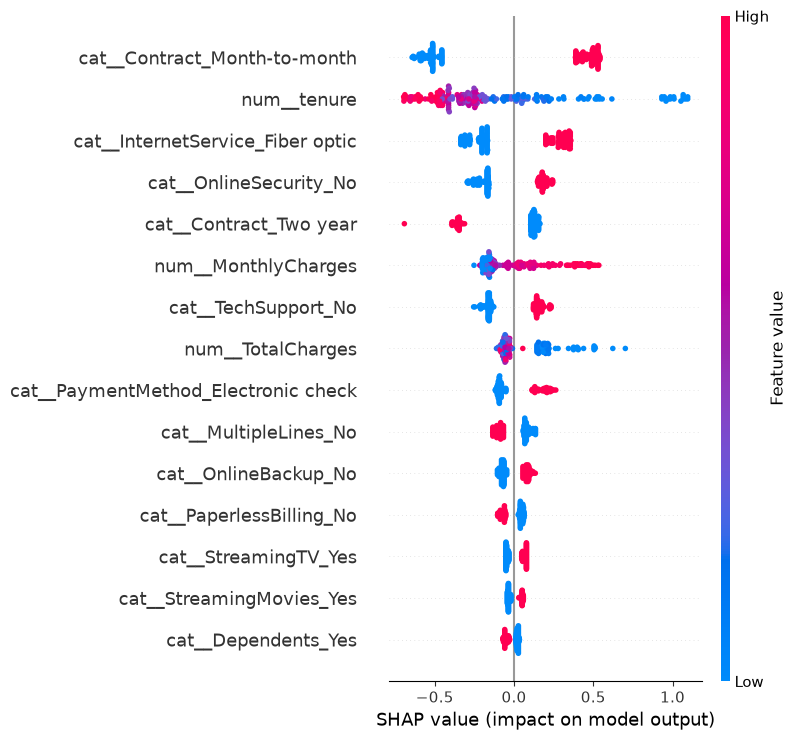

In [17]:
shap.summary_plot(
    shap_values,
    X_processed,
    feature_names=feature_names,
    max_display=15
)

In [18]:
import sqlalchemy

print("SQLAlchemy version:", sqlalchemy.__version__)

ImportError: DLL load failed while importing _collections_cy: An Application Control policy has blocked this file.